# Sparse-Grid Interpolation

This notebook implements the **Smolyak interpolation** surrogate (see Section 4.1.2) for the parametric diffusion problem.

In order to employ Smolyak interpolation to construct a surrogate of an operator
$\mathcal{G}: \mathcal{X} \to \mathcal{Y}$, we rely on an encoder
$\mathcal{E}: \mathcal{X} \to \mathbb{R}^{d_\mathcal{X}}$ and a decoder
$\mathcal{D}: \mathbb{R}^{d_\mathcal{Y}} \to \mathcal{Y}$ to map elements from the infinite-dimensional input and output spaces to finite-dimensional representations.  We then approximate
$$
g = \mathcal{D}^{-1} \circ \mathcal{G} \circ \mathcal{E}^{-1} : \mathbb{R}^{d_\mathcal{X}} \to \mathbb{R}^{d_\mathcal{Y}},
$$
with the interpolant
$$
  I^{\Lambda}[g](\bar{\mathbf{x}})
  = \sum_{\boldsymbol{\nu} \in \Lambda}
    \zeta_{\Lambda,\boldsymbol{\nu}}   I^{\boldsymbol{\nu}}[g](\bar{\mathbf{x}}).
$$
Here, $\Lambda \subset \mathbb{N}_0^{d_\mathcal{X}}$ is a multi-index set characterizing the polynomial space.

The operator surrogate is then given as 
$$
\hat{\mathcal{G}} = \mathcal{D} \circ I^{\Lambda}[g] \circ \mathcal{E}.
$$

For the following experiments, we use the [smolyax](https://github.com/JoWestermann/smolyax) library, which provides an efficient implementation of the interpolation operator suitable for high-dimensional inputs and outputs.

In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})

import jax
jax.config.update('jax_platform_name', 'cpu')

from smolyax import indices, nodes
from smolyax.interpolation import SmolyakBarycentricInterpolator

import error

from importer import import_notebook
import_notebook('0_Diffusion.ipynb', globals())        # provides: Grid, Diffusion
import_notebook('1_Representation.ipynb', globals())  # provides: Encoder, Decoder

In [2]:
d_in   = 50    # input dimension (sine-series modes)
d_out  = 50    # PCA rank (output dimension)
n_pca  = 500   # training samples for fitting the PCA basis
n_test = 100   # MC test samples
grid   = Grid(128)
decays = [1, 2, 3]
rng    = np.random.default_rng(0)

## 1. Sparse Grid Structure

As interpolation nodes, we choose the so-called Leja sequence (for more details see [Chkifa, 2015](https://doi.org/10.1007/978-3-319-22804-4_9)), which form a nested sequence of one-dimensional nodes and lead to a favorable operator norm of $I^\Lambda$.

In order to construct interpolants in higher dimensions, the Smolyak construction is parametrised by a multi-index set defining the multivariate polynomial space. Here, we choose an anisotropic multi-index set of the form
$$
  \Lambda_{\mathbf{k},t} = \bigl\{ \boldsymbol{\nu} \in \mathbb{N}_0^{d_\mathcal{X}}
  : \mathbf{k} \cdot \boldsymbol{\nu} \le t \bigr\},
$$
parametrised by **anisotropy weights** $k_j > 0$ and a **threshold** $t$ that controls the total
number of nodes $|\Lambda_{\mathbf{k},t}|$.  A larger weight $k_j$ penalises dimension $j$,
reducing the polynomial degree - and thus the number of nodes - allocated to it.

The two-dimensional example below compares an isotropic grid ($k_1 = k_2$) with an anisotropic
one ($k_2 \gg k_1$), at the same total node count.  The anisotropic grid concentrates nodes along
the more important first dimension.

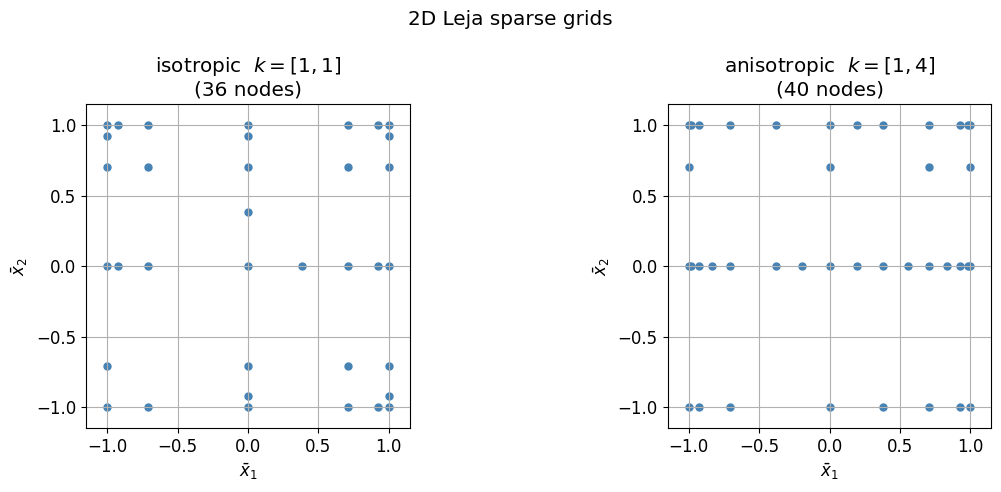

In [3]:
node_gen_2d = nodes.Leja(dim=2)
configs = [
    ('isotropic  $k = [1, 1]$',   [1., 1.]),
    ('anisotropic  $k = [1, 4]$', [1., 4.]),
]

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

for ax, (title, k_vals) in zip(axs, configs):
    t_vis = indices.find_approximate_threshold(k_vals, 40, node_gen_2d.is_nested)
    pts = []
    def f_vis(x, _pts=pts):
        _pts.append(np.array(x))
        return np.zeros(1)
    ip_vis = SmolyakBarycentricInterpolator(node_gen=node_gen_2d, k=k_vals, d_out=1, t=t_vis, f=f_vis)
    pts = np.array(pts)
    ax.scatter(pts[:, 0], pts[:, 1], s=25, color='steelblue')
    ax.set_title(f'{title}\n({ip_vis.n_f_evals} nodes)')
    ax.set_xlabel(r'$\bar{x}_1$'); ax.set_ylabel(r'$\bar{x}_2$')
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
    ax.set_aspect('equal'); ax.grid()

plt.suptitle('2D Leja sparse grids')
plt.tight_layout()
plt.show()

## 2. Convergence with Varying Smoothness

We consider the parametric diffusion problem from `0_Diffusion.ipynb`. The encoder
$\mathcal{E}$ is the log-normal sine-series map from `1_Representation.ipynb`: inputs
$x \in \mathcal{X}$ are parameterised by $\bar{\mathbf{x}} \in [-1,1]^{d_\mathcal{X}}$ via
$$
  x(\eta; \bar{\mathbf{x}}) = \exp\Bigl(\sum_{j=1}^{d_\mathcal{X}} \bar{x}_j \cdot j^{-\alpha} \cdot \sqrt{2}\sin(j\pi \eta)\Bigr),
$$
where $\alpha$ controls the decay rate $j^{-\alpha}$ of the Fourier coefficients; larger
$\alpha$ yields a smoother map $g$ and hence faster convergence of $I^\Lambda[g]$. The
decoder $\mathcal{D}$ is the data-driven PCA decoder from `1_Representation.ipynb`.

We test the interpolant for three smoothness levels $\alpha \in \{1, 2, 3\}$. The anisotropy
weights
$$
  k_j = \alpha \cdot \log(j + 1), \quad j = 1, \ldots, d_\mathcal{X},
$$
penalize higher-index dimensions, reflecting the ordering imposed by the $j^{-\alpha}$
coefficient decay.

For each smoothness level we:
1. Draw `n_pca` samples $\bar{\mathbf{x}} \sim \mathrm{Uniform}([-1,1]^{d_\mathcal{X}})$, compute
   $\mathcal{G}(\mathcal{E}^{-1}(\bar{\mathbf{x}}))$ for each, and fit the PCA decoder $\mathcal{D}$
   of rank $d_\mathrm{out}$;
2. Build Smolyak interpolants $g = I^\Lambda$ approximating
   $\bar{\mathbf{x}} \mapsto \mathcal{D}^{-1}(\mathcal{G}(\mathcal{E}^{-1}(\bar{\mathbf{x}})))$
   with **Leja nodes** on $[-1,1]$ at increasing thresholds $t$;
3. Evaluate $\hat{\mathcal{G}} = \mathcal{D} \circ g \circ \mathcal{E}$ on `n_test` test
   samples and measure the relative $L^2$ error.

In [4]:
xb_test = rng.uniform(-1., 1., (n_test, d_in))

node_gen  = nodes.Leja(dim=d_in)
n_targets = np.unique(np.round(np.geomspace(10, 2000, 9)).astype(int))

In [5]:
results = {}  # decay -> (n_nodes array, errors array)

for decay in decays:

    # --- PCA basis from training samples ---
    xb_pca  = rng.uniform(-1., 1., (n_pca, d_in))
    y_pca   = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in xb_pca])
    coder   = Decoder(rank=d_out, samples=y_pca.T)

    # --- reference solutions on the fixed test set ---
    y_test = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in xb_test])

    # --- anisotropy weights: k_j = decay * log(j+1) reflects j^{-decay} coefficient decay ---
    k = [decay * np.log(i + 2) for i in range(d_in)]

    # --- target function: xb -> D^{-1}(G(E^{-1}(xb))) ---
    def target(xb, _coder=coder, _decay=decay):
        xb = np.array(xb)
        return _coder.analyse(Diffusion(coefficient=Encoder(parameter=xb, decay=_decay))(grid))

    # --- sweep thresholds, reusing evaluations at nested Leja nodes ---
    f_evals  = None
    n_list   = []
    err_list = []

    for n_target in n_targets:
        t       = indices.find_approximate_threshold(k, int(n_target), node_gen.is_nested)
        ip      = SmolyakBarycentricInterpolator(node_gen=node_gen, k=k, d_out=d_out, t=t)
        f_evals = ip.set_f(f=target, f_evals=f_evals)
        y_pred  = coder.synthesise(np.array(ip(xb_test)))
        n_list.append(ip.n_f_evals)
        err_list.append(error.l2_rel(y_test, y_pred))

    results[decay] = (np.array(n_list), np.array(err_list))
    print(f'decay={decay}:  nodes {n_list[0]}..{n_list[-1]},  final error {err_list[-1]:.2e}')

decay=1:  nodes 9..1984,  final error 9.13e-03
decay=2:  nodes 12..1984,  final error 3.82e-05
decay=3:  nodes 12..2012,  final error 7.88e-07


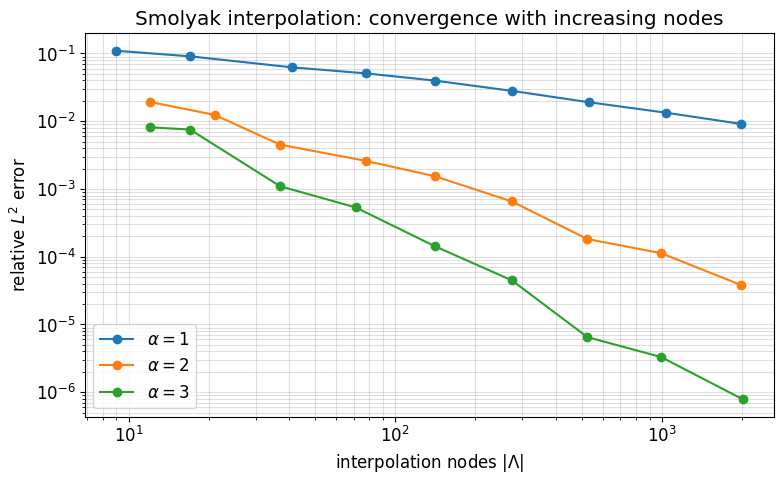

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

for decay in decays:
    n_nodes, errs = results[decay]
    ax.loglog(n_nodes, errs, marker='o', label=rf'$\alpha = {decay}$')

ax.set_xlabel(r'interpolation nodes $|\Lambda|$')
ax.set_ylabel('relative $L^2$ error')
ax.set_title('Smolyak interpolation: convergence with increasing nodes')
ax.legend()
ax.grid(which='both', alpha=0.4)
plt.tight_layout()
plt.show()